In [68]:
import os
import sys
import pickle
import glob
import json

import pandas as pd
import sqlite3
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.cluster import AgglomerativeClustering, HDBSCAN
from sklearn.metrics.pairwise import cosine_distances, cosine_similarity
from sklearn.model_selection import GroupShuffleSplit
from scipy import stats

%load_ext autoreload
%autoreload 2

pd.set_option('display.width', 1000)
pd.set_option('max_colwidth', 1000)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
BENCKMARK_PATHS = [
    "/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DLtest02_RV9",
    "/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DLtest_RV59",
    "/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_VLC_RV5_V2",
    "/mnt/pg-fs01/Current/DB/CV_PeopleTracking/Benchmarks/Mixed/VLC_MultiplePeopleCrossing/10fps",
]

In [22]:
SEQ_CSV_PATH = "../seq_files.csv"
df = pd.read_csv(SEQ_CSV_PATH)
df["camera_type"].fillna("unknown", inplace=True)
df["is_algo_test"] = df["seq_path"].apply(lambda pth: any([i in pth for i in BENCKMARK_PATHS]))
df.head()

/tmp/ipykernel_837721/509178424.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["camera_type"].fillna("unknown", inplace=True)


,seq_name,seq_path,avi_path,frame_h,frame_w,camera_type,altitude,is_algo_test
0,Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi,720.0,1280.0,unknown,253,False
1,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi,960.0,1280.0,SunPlus_PG_Camera,660,False
2,PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi,960.0,1280.0,SunPlus_PG1_Camera1,300,False
3,PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_VLC_RV5_V2/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_VLC/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi,960.0,1280.0,SunPlus_PG_Camera,270,True
4,PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DLtest02_RV9/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_DLtest02/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi,960.0,1280.0,SunPlus_PG_Camera,300,True


In [23]:
embedding_pths = sorted(glob.glob("embeddings/*"))
len(embedding_pths)

9634

In [24]:
avg_embeddings = []
for idx in range(len(embedding_pths)):
    with open(embedding_pths[idx], "rb") as f:
        embeddings = np.load(f)
    
    if embeddings.shape[0] == 0:
        print(embedding_pths[idx])
    else:
        avg_embeddings.append(np.mean(embeddings, axis=0))

print(len(avg_embeddings))

9634


In [25]:
mtx_sclearn_dist = cosine_distances(np.array(avg_embeddings).reshape(-1, 768))

In [26]:
clusters = AgglomerativeClustering(n_clusters=None, metric="precomputed", distance_threshold=0.4, linkage="average").fit(mtx_sclearn_dist)
np.unique(clusters.labels_).shape

(456,)

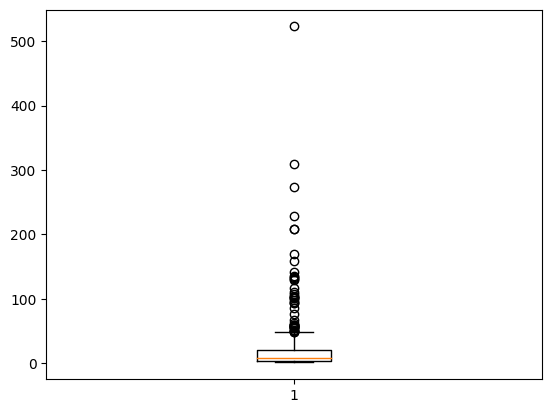

In [27]:
labels, counts = np.unique(clusters.labels_, return_counts=True)
plt.boxplot(counts);

In [28]:
df.head()

,seq_name,seq_path,avi_path,frame_h,frame_w,camera_type,altitude,is_algo_test
0,Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/Occupancy/OCS_people_counting_H253_B_PIRar/Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi,720.0,1280.0,unknown,253,False
1,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev2_high_height_Q/PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_1509285767.avi,960.0,1280.0,SunPlus_PG_Camera,660,False
2,PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_DL/PG1_DL_training_POS10_Walking/PG1_DL_H300_Walking_NY_St1707_1500538480.avi,960.0,1280.0,SunPlus_PG1_Camera1,300,False
3,PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_VLC_RV5_V2/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_VLC/PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343.avi,960.0,1280.0,SunPlus_PG_Camera,270,True
4,PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DLtest02_RV9/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling_POV/PG1_PIR2chnl/PG1_AlgoDev_DLtest02/PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.avi,960.0,1280.0,SunPlus_PG_Camera,300,True


In [29]:
df["is_algo_test"].sum()

477

In [30]:
seq_names = np.array([f"{os.path.basename(i)}.avi.seq" for i in embedding_pths])
group_ids = clusters.labels_.copy()

avg_embeddings = np.squeeze(avg_embeddings, axis=1)

algo_test_mapping = {row["seq_name"]: row["is_algo_test"] for _, row in df.iterrows()}
is_algo_test = np.array([algo_test_mapping[i] for i in seq_names])

algo_test_seq_names = seq_names[is_algo_test]
algo_test_group_ids = group_ids[is_algo_test]

seq_names = seq_names[~is_algo_test]
group_ids = group_ids[~is_algo_test]

algo_test_avg_embeddings = avg_embeddings[is_algo_test]
avg_embeddings = avg_embeddings[~is_algo_test]

In [31]:
def get_dist(a, b):
    dist = cosine_distances(a, b)
    dist = np.triu(dist, k = 1)
    dist = dist[dist > 0]
    return dist.mean()

In [58]:
def split_dataset(x, group_ids, embeddings, algo_test_avg_embeddings, val_size: float = 0.05, randon_seed: int = 44, num_skip_valid_splits: int = 0, th=0.2):
    n_splits = round(1 / val_size)
    gskf = GroupShuffleSplit(n_splits=n_splits, random_state=randon_seed)
    current_try = 0
    # Add check for classes and groups
    for index, indices in enumerate(gskf.split(x, groups=group_ids)):
        print(f"Trying split # {index}")
        train_indexes, test_indexes = indices
        train_ids = x[train_indexes]
        test_ids = x[test_indexes]

        train_inner_dist = get_dist(embeddings[train_indexes], embeddings[train_indexes])
        test_inner_dist = get_dist(embeddings[test_indexes], embeddings[test_indexes])
        outer_dist = get_dist(embeddings[train_indexes], embeddings[test_indexes])
        algo_outer_dist = get_dist(embeddings[test_indexes], algo_test_avg_embeddings)
        algo_inner_dist = get_dist(algo_test_avg_embeddings, algo_test_avg_embeddings)

        is_satisfactory_split = (outer_dist > train_inner_dist and outer_dist > test_inner_dist) and \
            (algo_outer_dist > algo_inner_dist and algo_outer_dist > test_inner_dist)
        if is_satisfactory_split and len(test_indexes) / len(x) <= th:
            if current_try >= num_skip_valid_splits:
                print("OK")
                break
            else:
                current_try += 1
        elif index == n_splits-1:
            print("not OK")
            break
    
    return train_indexes, test_indexes, train_ids, test_ids

In [59]:
train_ids, hold_out_ids, train_seq_names, hold_out_seq_names = split_dataset(seq_names, group_ids, avg_embeddings, algo_test_avg_embeddings)

Trying split # 0
Trying split # 1
Trying split # 2
OK


In [60]:
len(train_seq_names), len(hold_out_seq_names)


(7544, 1613)

In [61]:
train_ids, val_ids, train_seq_names, val_seq_names = split_dataset(
    seq_names[train_ids], group_ids[train_ids], avg_embeddings[train_ids], algo_test_avg_embeddings, val_size=0.1)

Trying split # 0
Trying split # 1
Trying split # 2
Trying split # 3
Trying split # 4
Trying split # 5
OK


In [63]:
len(train_seq_names), len(val_seq_names)

(6434, 1110)

In [67]:
set(train_seq_names).intersection(val_seq_names), set(train_seq_names).intersection(hold_out_seq_names),\
    set(val_seq_names).intersection(hold_out_seq_names)

(set(), set(), set())

In [70]:
with open("splitting.json", "wt") as f:
    json.dump({
        "train": train_seq_names.tolist(),
        "val": val_seq_names.tolist(),
        "hold-out": hold_out_seq_names.tolist()
    }, f, indent=4)